# Chapter 13: One factor, again and again

Checks [chapter 13](../../book/13-one-factor.md). The model is **linear in its weights**: its outputs on the data are
`matrix @ weights`, a Fourier series with fixed frequencies whose sine and cosine coefficients are the weights (each column
scaled down by its frequency, so the strengths spread over a wide range), fitted to 60 random inputs with 21 weights.
Gradient descent on `0.5 * sum(residual ** 2) / num_points` moves the weight error along each eigenvector of the kernel
`matrix.T @ matrix / num_points` by the factor `1 - learning_rate * strength`, where `strength` is the eigenvalue. The
**weight error** is `weights - best_weights`, with `best_weights` the least-squares fit (what gradient descent converges to).
Everything is NumPy in float64, seeded. These are measurements, not proofs: the proofs are in `SpectralBias.lean`,
`EdgeOfStability.lean`, `WeightDecay.lean`, `Optimisers.lean`, `BatchSize.lean` and `StepRules.lean`.
Run every cell, top to bottom. A failed check stops the notebook.

In [1]:
import sys
sys.path.append("../part1")

import numpy as np
from common import use_style, save_figure, report, NEAREST, VERTICAL, BOUND, MODEL, BEFORE
import matplotlib.pyplot as plt

use_style()
NUM_POINTS = 60
NUM_WEIGHTS = 21
SEED = 13


def build_fourier_matrix(inputs, num_weights):
    """Constant, then sin(k x) and cos(k x) for k = 1, 2, ..., each scaled by sqrt(2)."""
    columns = [np.ones_like(inputs)]
    for frequency in range(1, (num_weights - 1) // 2 + 1):
        columns.append(np.sqrt(2) * np.sin(frequency * inputs))
        columns.append(np.sqrt(2) * np.cos(frequency * inputs))
    return np.stack(columns, axis=1)


def build_problem(seed, signal_terms=3, noise_size=0.5):
    """Random inputs, a smooth signal on the first few terms, plus noise on every direction."""
    generator = np.random.default_rng(seed)
    inputs = np.sort(generator.uniform(0, 2 * np.pi, NUM_POINTS))
    matrix = build_fourier_matrix(inputs, NUM_WEIGHTS)
    column_scale = 1.0 / np.maximum(1, (np.arange(NUM_WEIGHTS) + 1) // 2)
    matrix = matrix * column_scale
    signal_weights = np.zeros(NUM_WEIGHTS)
    signal_weights[: 2 * signal_terms + 1] = generator.standard_normal(2 * signal_terms + 1)
    clean_labels = matrix @ signal_weights
    labels = clean_labels + noise_size * generator.standard_normal(NUM_POINTS)
    return matrix, labels, clean_labels, signal_weights


def get_kernel_eigen(matrix):
    """Kernel, its strengths (eigenvalues, strongest first) and directions (columns)."""
    kernel = matrix.T @ matrix / len(matrix)
    strengths, directions = np.linalg.eigh(kernel)
    order = np.argsort(strengths)[::-1]
    return kernel, strengths[order], directions[:, order]


def take_gradient_step(matrix, labels, weights, learning_rate):
    residual = labels - matrix @ weights
    return weights + learning_rate * matrix.T @ residual / len(labels)


def run_gradient_descent(matrix, labels, start_weights, learning_rate, num_steps):
    """Weights after each step, rows 0..num_steps."""
    history = [start_weights]
    for step in range(num_steps):
        history.append(take_gradient_step(matrix, labels, history[-1], learning_rate))
    return np.array(history)


matrix, labels, clean_labels, signal_weights = build_problem(SEED)
kernel, strengths, directions = get_kernel_eigen(matrix)
best_weights = np.linalg.lstsq(matrix, labels, rcond=None)[0]
best_along = best_weights @ directions
print(f"strengths: strongest {strengths[0]:.3f}, weakest {strengths[-1]:.2e}, ratio {strengths[0] / strengths[-1]:.0f}")

strengths: strongest 1.198, weakest 3.40e-03, ratio 352


## Claim 1: strong directions are learned first, each on its own clock (`SpectralBias`)

Start at zero weights, learning rate `0.5 / strongest strength`. Project the weight error on each kernel direction. The
theorem says the component along a direction with strength `s` is multiplied by `1 - learning_rate * s` per step. Checked
two ways: the projected error after `t` steps equals `(1 - learning_rate * s) ** t` times the start, for every direction
and several `t`; and the number of steps until 90 percent of the component is gone, `log(0.1) / log(1 - learning_rate * s)`,
is non-decreasing as strength falls. The control: the strongest direction's formula must not fit the weakest direction.

[PASS] each direction's error is the start times (1 - learning_rate * strength) ** t, for t = 1, 5, 50, 400  (largest gap 5.6e-15)
[PASS] the 90-percent clock is non-decreasing as strength falls (strong first)  (clock from 3.3 to 1622 steps)
[PASS] measured clocks equal ceil(formula) wherever the run is long enough  (15 of 21 directions reach 90 percent in 400 steps)
[PASS] control: the strongest direction's formula does not fit the weakest direction


wrote book/figures/13-own-clocks.png


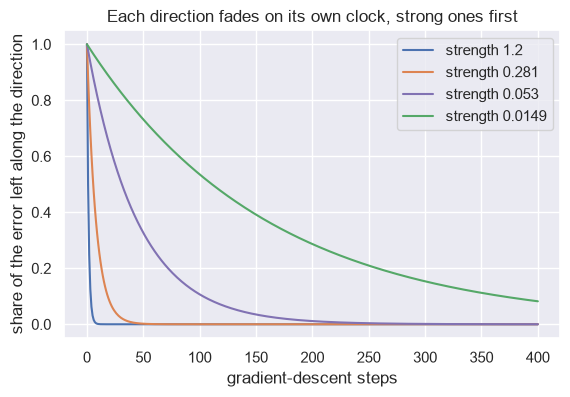

In [2]:
learning_rate = 0.5 / strengths[0]
history = run_gradient_descent(matrix, labels, np.zeros(NUM_WEIGHTS), learning_rate, 400)
error_components = (history - best_weights) @ directions          # row t, column direction
factors = 1 - learning_rate * strengths

worst_gap = 0.0
for step in (1, 5, 50, 400):
    predicted = factors ** step * error_components[0]
    worst_gap = max(worst_gap, np.abs(error_components[step] - predicted).max())
report("each direction's error is the start times (1 - learning_rate * strength) ** t, for t = 1, 5, 50, 400",
       worst_gap < 1e-9, f"largest gap {worst_gap:.1e}")

clock_90 = np.log(0.1) / np.log(factors)                        # steps to remove 90 percent
below = np.abs(error_components) <= 0.1 * np.abs(error_components[0])
reachable = below.any(axis=0)
measured_90 = np.argmax(below, axis=0)
report("the 90-percent clock is non-decreasing as strength falls (strong first)",
       bool(np.all(np.diff(clock_90) >= -1e-12)), f"clock from {clock_90[0]:.1f} to {clock_90[-1]:.0f} steps")
report("measured clocks equal ceil(formula) wherever the run is long enough",
       bool(np.all(measured_90[reachable] == np.ceil(clock_90[reachable]))),
       f"{int(reachable.sum())} of {NUM_WEIGHTS} directions reach 90 percent in 400 steps")
report("control: the strongest direction's formula does not fit the weakest direction",
       abs(factors[0] ** 400 - factors[-1] ** 400) > 0.5)

figure, axis = plt.subplots(figsize=(6.4, 4))
for index, color in ((0, NEAREST), (3, VERTICAL), (8, MODEL), (14, BOUND)):
    axis.plot(np.abs(error_components[:, index]) / abs(error_components[0, index]), color=color,
              label=f"strength {strengths[index]:.3g}")
axis.set_xlabel("gradient-descent steps")
axis.set_ylabel("share of the error left along the direction")
axis.set_title("Each direction fades on its own clock, strong ones first")
axis.legend()
save_figure(figure, "13-own-clocks")
plt.show()

## Claim 2: stopping early keeps out the weak directions (`SpectralBias`)

The labels are a smooth signal plus noise. The noise has a part in every direction; the signal sits in the strongest ones.
Measure the error against the clean signal on the data after each step (20 000 steps). It must fall, reach a minimum well
before the end, and rise again as the weak directions fit noise. At the best stopping step, the strong directions are almost
learned and the weak ones are mostly not.

[PASS] the error against the clean signal has its minimum before the end and rises after it  (minimum 0.132 at step 38, end 0.243)
[PASS] at the best stopping step the strongest direction is more than 99 percent learned  (learned share: strongest 1.000)
[PASS] ... and the weakest five directions are less than half learned  (weakest five [0.145 0.123 0.119 0.083 0.053])


wrote book/figures/13-early-stopping.png


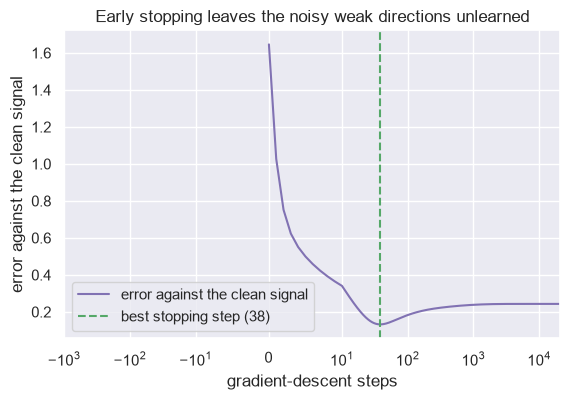

In [3]:
learning_rate = 0.5 / strengths[0]
history = run_gradient_descent(matrix, labels, np.zeros(NUM_WEIGHTS), learning_rate, 20000)
clean_error = np.sqrt(np.mean((history @ matrix.T - clean_labels) ** 2, axis=1))
best_step = int(np.argmin(clean_error))
learned = 1 - np.abs((history[best_step] - best_weights) @ directions) / np.abs(best_along)
report("the error against the clean signal has its minimum before the end and rises after it",
       0 < best_step < len(history) - 1 and clean_error[-1] > 1.05 * clean_error[best_step],
       f"minimum {clean_error[best_step]:.3f} at step {best_step}, end {clean_error[-1]:.3f}")
report("at the best stopping step the strongest direction is more than 99 percent learned",
       learned[0] > 0.99, f"learned share: strongest {learned[0]:.3f}")
report("... and the weakest five directions are less than half learned",
       bool(np.all(learned[-5:] < 0.5)), f"weakest five {np.round(learned[-5:], 3)}")

figure, axis = plt.subplots(figsize=(6.4, 4))
axis.plot(clean_error, color=MODEL, label="error against the clean signal")
axis.axvline(best_step, color=BOUND, linestyle="--", label=f"best stopping step ({best_step})")
axis.set_xscale("symlog", linthresh=10)
axis.set_xlabel("gradient-descent steps")
axis.set_ylabel("error against the clean signal")
axis.set_title("Early stopping leaves the noisy weak directions unlearned")
axis.legend()
save_figure(figure, "13-early-stopping")
plt.show()

## Claim 3: the error shrinks, holds or grows as learning rate times strength is below, at or above 2 (`EdgeOfStability`)

Take the strongest direction and set `learning_rate * strength` to 0.5, 1.9, 2.0 and 2.1. Start with weight error 1 along
that direction and run 60 real gradient steps. At 1.9 the size must shrink, at 2.0 it must stay equal to 1 to rounding
(its sign flips each step), at 2.1 it must grow, each as `abs(1 - learning_rate * strength) ** steps`.

learning_rate x strength = 0.5: size after 60 steps 7.638e-16, formula 8.674e-19
learning_rate x strength = 1.9: size after 60 steps 0.001797, formula 0.001797
learning_rate x strength = 2.0: size after 60 steps 1, formula 1
learning_rate x strength = 2.1: size after 60 steps 304.5, formula 304.5
[PASS] below 2 (1.9) the error shrinks at every step  (size 0.001797)
[PASS] at 2 the error holds: size 1 after 60 steps, to rounding  (size 1.000000000000)
[PASS] above 2 (2.1) the error grows at every step  (size 304.5)
[PASS] every row equals abs(1 - learning_rate * strength) ** steps


wrote book/figures/13-edge-of-stability.png


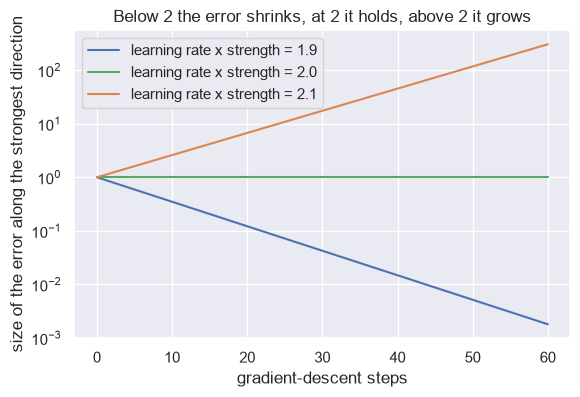

In [4]:
top_direction = directions[:, 0]
rows = {}
for product in (0.5, 1.9, 2.0, 2.1):
    learning_rate = product / strengths[0]
    weights = best_weights + top_direction                      # error 1 along the strongest direction
    sizes = [1.0]
    for step in range(60):
        weights = take_gradient_step(matrix, labels, weights, learning_rate)
        sizes.append(abs((weights - best_weights) @ top_direction))
    rows[product] = np.array(sizes)
    print(f"learning_rate x strength = {product}: size after 60 steps {sizes[-1]:.4g}, formula {abs(1 - product) ** 60:.4g}")
report("below 2 (1.9) the error shrinks at every step", rows[1.9][-1] < 0.1 and bool(np.all(np.diff(rows[1.9]) < 0)),
       f"size {rows[1.9][-1]:.4g}")
report("at 2 the error holds: size 1 after 60 steps, to rounding", abs(rows[2.0][-1] - 1) < 1e-9,
       f"size {rows[2.0][-1]:.12f}")
report("above 2 (2.1) the error grows at every step", rows[2.1][-1] > 10 and bool(np.all(np.diff(rows[2.1]) > 0)),
       f"size {rows[2.1][-1]:.4g}")
report("every row equals abs(1 - learning_rate * strength) ** steps",
       all(np.allclose(rows[product], abs(1 - product) ** np.arange(61), rtol=1e-8, atol=1e-12) for product in rows))

figure, axis = plt.subplots(figsize=(6.4, 4))
for product, color in ((1.9, NEAREST), (2.0, BOUND), (2.1, VERTICAL)):
    axis.plot(rows[product], color=color, label=f"learning rate x strength = {product}")
axis.set_yscale("log")
axis.set_xlabel("gradient-descent steps")
axis.set_ylabel("size of the error along the strongest direction")
axis.set_title("Below 2 the error shrinks, at 2 it holds, above 2 it grows")
axis.legend()
save_figure(figure, "13-edge-of-stability")
plt.show()

## Claim 4: weight decay leaves the share `decay / (strength + decay)`; stopping cuts at least as hard (`WeightDecay`)

Ridge fit: the weights minimising `0.5 * mean(residual ** 2) + 0.5 * decay * norm(weights) ** 2`, which is
`(kernel + decay * I)^-1 @ matrix.T @ labels / num_points`. The share of the best weights' components left as error along each
direction is compared with `decay / (strength + decay)`. Then, for `step_count` in 10, 100, 1000, set
`decay = 1 / (learning_rate * step_count)`, run that many real gradient steps from zero at learning rate
`0.5 / strongest strength`, and compare the share left along every direction with the stopped bound
`1 / (1 + step_count * learning_rate * strength)` and with the ridge share: the stopped share must be at most both (the
theorem needs `learning_rate * strength <= 1`, true here). Control: a decay ten times smaller than the matching one must
leave a smaller share than stopping somewhere, so the matching decay is not slack in every direction.

[PASS] ridge leaves the share decay / (strength + decay) along every direction, for 4 decay values  (largest gap 2.3e-14)
[PASS] 10 steps: stopped share <= 1 / (1 + steps * rate * strength) and <= ridge share at decay 1 / (rate * steps)  (largest stopped/ridge ratio 1.000)
[PASS] 100 steps: stopped share <= 1 / (1 + steps * rate * strength) and <= ridge share at decay 1 / (rate * steps)  (largest stopped/ridge ratio 0.991)
[PASS] 1000 steps: stopped share <= 1 / (1 + steps * rate * strength) and <= ridge share at decay 1 / (rate * steps)  (largest stopped/ridge ratio 0.585)
[PASS] control: a ten times smaller decay leaves less than stopping in some direction (the check can fail)


wrote book/figures/13-decay-and-stopping.png


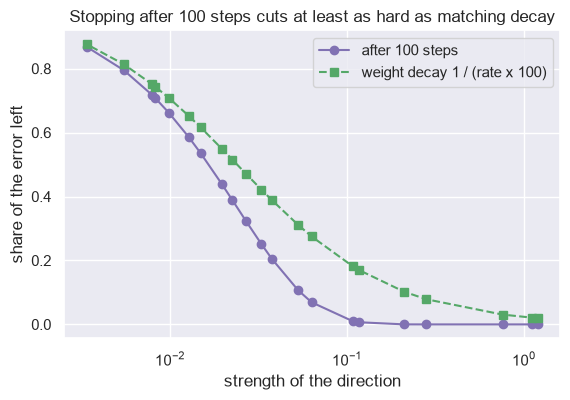

In [5]:
worst_gap = 0.0
for decay in (1e-3, 1e-2, 1e-1, 1.0):
    ridge_weights = np.linalg.solve(kernel + decay * np.eye(NUM_WEIGHTS), matrix.T @ labels / NUM_POINTS)
    share = (best_weights - ridge_weights) @ directions / best_along
    worst_gap = max(worst_gap, np.abs(share - decay / (strengths + decay)).max())
report("ridge leaves the share decay / (strength + decay) along every direction, for 4 decay values",
       worst_gap < 1e-9, f"largest gap {worst_gap:.1e}")

learning_rate = 0.5 / strengths[0]
rows = {}
for step_count in (10, 100, 1000):
    decay = 1 / (learning_rate * step_count)
    stopped = run_gradient_descent(matrix, labels, np.zeros(NUM_WEIGHTS), learning_rate, step_count)[-1]
    stopped_share = (best_weights - stopped) @ directions / best_along
    bound = 1 / (1 + step_count * learning_rate * strengths)
    ridge_share = decay / (strengths + decay)
    rows[step_count] = (stopped_share, bound, ridge_share)
    report(f"{step_count} steps: stopped share <= 1 / (1 + steps * rate * strength) and <= ridge share at decay 1 / (rate * steps)",
           bool(np.all(stopped_share <= bound + 1e-12)) and bool(np.all(stopped_share <= ridge_share + 1e-12)),
           f"largest stopped/ridge ratio {np.max(stopped_share / ridge_share):.3f}")
stopped_share = rows[100][0]
small_decay = 0.1 / (learning_rate * 100)
report("control: a ten times smaller decay leaves less than stopping in some direction (the check can fail)",
       bool(np.any(small_decay / (strengths + small_decay) < stopped_share)))

figure, axis = plt.subplots(figsize=(6.4, 4))
axis.plot(strengths, rows[100][0], "o-", color=MODEL, label="after 100 steps")
axis.plot(strengths, rows[100][2], "s--", color=BOUND, label="weight decay 1 / (rate x 100)")
axis.set_xscale("log")
axis.set_xlabel("strength of the direction")
axis.set_ylabel("share of the error left")
axis.set_title("Stopping after 100 steps cuts at least as hard as matching decay")
axis.legend()
save_figure(figure, "13-decay-and-stopping")
plt.show()

## Claim 5: a schedule leaves the product of the factors (`Optimisers`)

Two learning-rate schedules of 50 steps: random rates up to `1.5 / strongest strength`, and a decaying one
`0.9 / strongest strength / (1 + step / 10)`. The error along every direction after the schedule must equal the start times
`prod(1 - learning_rate[step] * strength)`. The control: using only the mean rate, `(1 - mean_rate * strength) ** 50`, gives a
different answer, so the check could fail.

In [6]:
generator = np.random.default_rng(SEED + 1)
schedules = {"random": generator.uniform(0, 1.5, 50) / strengths[0],
             "decaying": 0.9 / strengths[0] / (1 + np.arange(50) / 10)}
for name, rates in schedules.items():
    weights = np.zeros(NUM_WEIGHTS)
    for rate in rates:
        weights = take_gradient_step(matrix, labels, weights, rate)
    measured = (weights - best_weights) @ directions
    product = np.prod(1 - np.outer(rates, strengths), axis=0) * (-best_along)
    gap = np.abs(measured - product).max()
    mean_rate_guess = (1 - rates.mean() * strengths) ** 50 * (-best_along)
    mean_gap = np.abs(measured - mean_rate_guess).max()
    report(f"{name} schedule: the error along every direction is the start times the product of the factors",
           gap < 1e-9 and mean_gap > 1e-6, f"largest gap {gap:.1e}; the mean-rate guess is off by {mean_gap:.2e}")

[PASS] random schedule: the error along every direction is the start times the product of the factors  (largest gap 5.5e-15; the mean-rate guess is off by 1.13e-03)
[PASS] decaying schedule: the error along every direction is the start times the product of the factors  (largest gap 5.5e-15; the mean-rate guess is off by 2.35e-03)


## Claim 6: two steps on two batches against one step on both (`BatchSize`)

Split the 60 points into two batches of 30. The push on a batch is `matrix_batch.T @ residual_batch` (summed). Two steps
(first batch, then second) differ from one step on both batches by exactly
`learning_rate ** 2 * matrix_second.T @ matrix_second @ matrix_first.T @ residual_first`, the term in the theorem. Checked to
rounding. Then the gap is measured at learning rates `1e-5` to `1e-2`: its log-log slope must be 2, the order
`learning_rate ** 2`. The control: a gap of order `learning_rate` would have slope 1.

[PASS] two steps = one step on both minus the stated correction, to rounding  (largest gap relative to the correction 1.7e-09)
[PASS] the gap between two steps and one step grows as learning_rate ** 2 (log-log slope 2)  (slopes [2. 2. 2.])
[PASS] control: the gap is not of order learning_rate (that would be slope 1)


wrote book/figures/13-two-batches.png


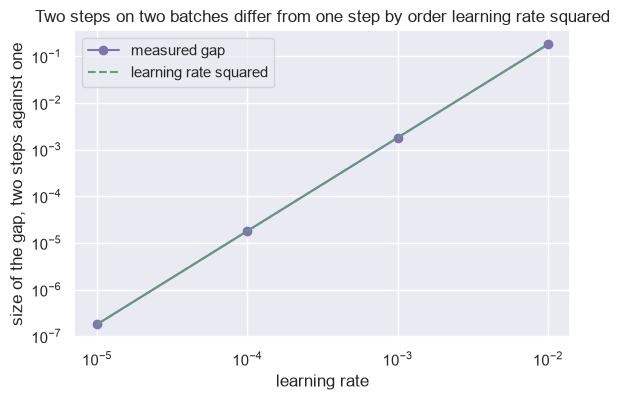

In [7]:
first = slice(0, NUM_POINTS // 2)
second = slice(NUM_POINTS // 2, NUM_POINTS)
first_matrix, second_matrix = matrix[first], matrix[second]
first_labels, second_labels = labels[first], labels[second]
generator = np.random.default_rng(SEED + 2)
start_weights = generator.standard_normal(NUM_WEIGHTS)


def push(batch_matrix, batch_labels, weights):
    return batch_matrix.T @ (batch_labels - batch_matrix @ weights)


gaps = []
formula_gap = 0.0
rates = (1e-5, 1e-4, 1e-3, 1e-2)
for rate in rates:
    after_first = start_weights + rate * push(first_matrix, first_labels, start_weights)
    two_steps = after_first + rate * push(second_matrix, second_labels, after_first)
    one_step = start_weights + rate * (push(first_matrix, first_labels, start_weights)
                                       + push(second_matrix, second_labels, start_weights))
    correction = rate ** 2 * second_matrix.T @ second_matrix @ first_matrix.T @ (
        first_labels - first_matrix @ start_weights)
    formula_gap = max(formula_gap, np.abs(two_steps - (one_step - correction)).max() / np.abs(correction).max())
    gaps.append(np.linalg.norm(two_steps - one_step))
report("two steps = one step on both minus the stated correction, to rounding", formula_gap < 1e-4,
       f"largest gap relative to the correction {formula_gap:.1e}")
slopes = np.diff(np.log(gaps)) / np.diff(np.log(rates))
report("the gap between two steps and one step grows as learning_rate ** 2 (log-log slope 2)",
       bool(np.all(np.abs(slopes - 2) < 0.02)), f"slopes {np.round(slopes, 3)}")
report("control: the gap is not of order learning_rate (that would be slope 1)", bool(np.all(slopes > 1.5)))

figure, axis = plt.subplots(figsize=(6.4, 4))
axis.loglog(rates, gaps, "o-", color=MODEL, label="measured gap")
axis.loglog(rates, gaps[0] * (np.array(rates) / rates[0]) ** 2, "--", color=BOUND, label="learning rate squared")
axis.set_xlabel("learning rate")
axis.set_ylabel("size of the gap, two steps against one")
axis.set_title("Two steps on two batches differ from one step by order learning rate squared")
axis.legend()
save_figure(figure, "13-two-batches")
plt.show()

## Claim 7: the sign rule closes a gap by the learning rate per step whatever the strength (`StepRules`)

With no memory, Adam steps by the sign of the gradient. Work in the kernel's own directions, where the kernel is diagonal
and the gradient along direction `i` is `strength_i * error_i`. Multiply the strengths by 0.01, 1 and 100 (scale the features by
the square root) so the runs differ by a factor 10 000. Start every coordinate's error at 0.5, take 20 sign steps at
learning rate 0.01 and track the largest error. It must fall by exactly 0.01 per step in all three runs. Control: one plain
gradient step leaves a different largest error in each run.

In [8]:
learning_rate = 0.01
gap_start = 0.5
eigen_matrix = matrix @ directions                                 # kernel is now diagonal
eigen_best = directions.T @ best_weights
rows = {}
for scale_strength in (0.01, 1.0, 100.0):
    scaled_matrix = eigen_matrix * np.sqrt(scale_strength)
    scaled_best = eigen_best / np.sqrt(scale_strength)
    weights = scaled_best + gap_start * np.ones(NUM_WEIGHTS)
    start = weights.copy()
    largest_gaps = [np.abs(weights - scaled_best).max()]
    for step in range(20):
        gradient = -scaled_matrix.T @ (labels - scaled_matrix @ weights) / NUM_POINTS
        weights = weights - learning_rate * np.sign(gradient)
        largest_gaps.append(np.abs(weights - scaled_best).max())
    plain = take_gradient_step(scaled_matrix, labels, start, learning_rate)
    rows[scale_strength] = (np.array(largest_gaps), np.abs(plain - scaled_best)[0])
    print(f"strength x {scale_strength}: sign-step gap falls {largest_gaps[0] - largest_gaps[1]:.6f} per step; "
          f"a plain gradient step leaves {rows[scale_strength][1]:.4f} on the strongest direction")
report("the sign step closes the largest gap by exactly the learning rate per step, at all three strengths",
       all(np.allclose(np.diff(row[0]), -learning_rate, atol=1e-9) for row in rows.values()))
plain_gaps = [row[1] for row in rows.values()]
report("control: one plain gradient step leaves a different gap at each strength (the check can fail)",
       max(plain_gaps) - min(plain_gaps) > 1e-2, f"{np.round(plain_gaps, 4)}")

strength x 0.01: sign-step gap falls 0.010000 per step; a plain gradient step leaves 0.4999 on the strongest direction
strength x 1.0: sign-step gap falls 0.010000 per step; a plain gradient step leaves 0.4940 on the strongest direction
strength x 100.0: sign-step gap falls 0.010000 per step; a plain gradient step leaves 0.0989 on the strongest direction
[PASS] the sign step closes the largest gap by exactly the learning rate per step, at all three strengths
[PASS] control: one plain gradient step leaves a different gap at each strength (the check can fail)  ([0.4999 0.494  0.0989])


True

## The second table: a signal through layers, gain below, at and above one

A stack of 50 linear layers, each a random orthogonal matrix times `gain`, so every layer multiplies the length of any
signal by exactly `gain`. Send 20 random signals through. The length after `depth` layers must equal `gain ** depth`: dying
below one, carried unchanged at one, exploding above one. The control: 50 random layers that are not orthogonal
(Gaussian entries over the square root of the width, average gain one) do not multiply every signal by the same factor.

gain 0.8: mean length after 50 layers 1.427e-05, formula 1.427e-05
[PASS] gain 0.8: every signal's length after 50 layers is gain ** 50
gain 1.0: mean length after 50 layers 1, formula 1
[PASS] gain 1.0: every signal's length after 50 layers is gain ** 50
gain 1.2: mean length after 50 layers 9100, formula 9100
[PASS] gain 1.2: every signal's length after 50 layers is gain ** 50
[PASS] below one it dies, at one it is carried, above one it explodes
[PASS] control: random non-orthogonal layers do not give one factor for every signal (the check can fail)  (spread of log-length 0.88)
wrote book/figures/13-gain-through-layers.png


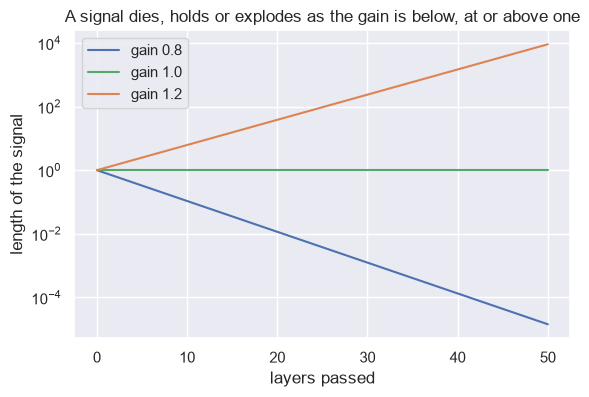

In [9]:
generator = np.random.default_rng(SEED + 3)
DEPTH = 50
WIDTH = 32
signals = generator.standard_normal((20, WIDTH))
signals /= np.linalg.norm(signals, axis=1, keepdims=True)
lengths = {}
for gain in (0.8, 1.0, 1.2):
    state = signals.copy()
    path = [np.ones(len(signals))]
    for layer in range(DEPTH):
        orthogonal, _ = np.linalg.qr(generator.standard_normal((WIDTH, WIDTH)))
        state = gain * state @ orthogonal.T
        path.append(np.linalg.norm(state, axis=1))
    lengths[gain] = np.array(path)
    print(f"gain {gain}: mean length after {DEPTH} layers {lengths[gain][-1].mean():.4g}, formula {gain ** DEPTH:.4g}")
    report(f"gain {gain}: every signal's length after {DEPTH} layers is gain ** {DEPTH}",
           np.allclose(lengths[gain][-1], gain ** DEPTH, rtol=1e-9))
report("below one it dies, at one it is carried, above one it explodes",
       lengths[0.8][-1].max() < 1e-3 and np.allclose(lengths[1.0][-1], 1) and lengths[1.2][-1].min() > 1e3)

state = signals.copy()
for layer in range(DEPTH):
    random_layer = generator.standard_normal((WIDTH, WIDTH)) / np.sqrt(WIDTH)
    state = state @ random_layer.T
spread = np.std(np.log(np.linalg.norm(state, axis=1)))
report("control: random non-orthogonal layers do not give one factor for every signal (the check can fail)",
       spread > 0.1, f"spread of log-length {spread:.2f}")

figure, axis = plt.subplots(figsize=(6.4, 4))
for gain, color in ((0.8, NEAREST), (1.0, BOUND), (1.2, VERTICAL)):
    axis.plot(lengths[gain].mean(axis=1), color=color, label=f"gain {gain}")
axis.set_yscale("log")
axis.set_xlabel("layers passed")
axis.set_ylabel("length of the signal")
axis.set_title("A signal dies, holds or explodes as the gain is below, at or above one")
axis.legend()
save_figure(figure, "13-gain-through-layers")
plt.show()